# Holding a survey out: what the calibrated backbone predicts for a plant it has not seen

**Question:** When the calibrated backbone is refitted without one survey, how well does it predict that survey's throughput, and how much better is that than guessing the mean of the others?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 05-real-surveys
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- explain what a leave-one-survey-out fold is, and say which rows it fits and which it predicts;
- read the held-out prediction of the calibrated backbone for each of the ten surveys;
- compare it with the constant-mean baseline that a model with no skill would give;
- say how much the in-sample judgement of the same model flatters it.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader and the two builders of the pipeline's `hp500` folder: the backbone and CrusherCal.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys, the engine's results at them, and the committed CrusherCal document. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` and `data/derived/hp500/loo.json` (contract `hp500-loo`), the last one only to check that the live computation reproduces it.

The cell below reads everything and runs the whole validation live. The document it builds is the committed one, which is the notebook's single reproduction check; everything after it uses the live document.

In [2]:
# Rebuild the backbone and the CrusherCal document live from the survey table; they must be the committed ones
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("rebuilt CrusherCal document equals the committed one:", doc == committed, "| surveys:", doc["n"])

rebuilt CrusherCal document equals the committed one: True | surveys: 10


## Method

**Step 1, the fold.** A model that is fitted to ten surveys and judged on the same ten tells how well it describes them, not how it would do on an eleventh. The leave-one-survey-out protocol answers the second question: for each survey $i$, fit on the other nine and predict $i$, then judge the ten predictions together. The backbone's only free number for the throughput is the capacity base $Q_T$, which each fold refits to its nine surveys by least squares. The pipeline's CrusherCal code builds the folds with a helper, and the cell prints the training rows of survey 3 in the strict fold and in the leaky variant, which keeps the survey in its own training set and exists to measure how much that flatters a model.

In [3]:
# Training rows for survey 3 (index 2) in the strict fold and in the leaky variant
print("strict fold, rows fitted:", loo._loo_indices(10, 2, leaky=False).tolist())
print("leaky variant, rows fitted:", loo._loo_indices(10, 2, leaky=True).tolist())

strict fold, rows fitted: [0, 1, 3, 4, 5, 6, 7, 8, 9]
leaky variant, rows fitted: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


The two predictions for survey 3 can be made with the pipeline's own model functions, which `loo.build` calls fold by fold: the backbone M0, whose prediction is the capacity base fitted to the training rows times the survey's capacity factor, and the free-form regression M2 on the setting and the f80. The cell asks for both in the strict fold and in the leaky one, next to the measurement.

In [4]:
# Predict survey 3 with the pipeline's M0 and M2 functions, in the strict fold and in the leaky variant
shape = np.array([s["backbone"]["throughput_tph"] for s in live_backbone["surveys"]]) / HP500_QREF
measured = np.array([s.feed_tph for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
for name, leaky in (("strict", False), ("leaky", True)):
    rows = loo._loo_indices(10, 2, leaky=leaky)
    print(f"{name:7s} M0 {loo._m0_tph(shape, measured, 2, rows):7.1f} t/h   M2 {loo._m2_freeform(features, measured, 2, rows):7.1f} t/h   measured {measured[2]:.0f} t/h")

strict  M0  1165.8 t/h   M2   981.0 t/h   measured 1240 t/h
leaky   M0  1173.4 t/h   M2  1078.3 t/h   measured 1240 t/h


The leaky fold, which has seen survey 3, lands nearer to the measurement than the strict one for both models, and the free-form regression gains the most from the leak, as it has the most coefficients to bend towards the point it saw. The capacity base of the backbone is the one number each fold refits, and the next cell prints it for the ten strict folds.

In [5]:
# The capacity base refitted by each of the ten strict folds
bases = [loo._m0_tph(shape, measured, i, loo._loo_indices(10, i, False)) / shape[i] for i in range(10)]
print("refitted capacity base per fold [t/h]:", np.round(bases, 1))
print("range:", round(min(bases), 1), "to", round(max(bases), 1), "| the paper's value:", HP500_QREF)

refitted capacity base per fold [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
range: 659.3 to 698.3 | the paper's value: 647


The base moves between 659 and 698 t/h from fold to fold, a spread of about 6 percent produced by removing one survey out of ten, and every fold sits above the paper's 647 t/h: that is how much a one-parameter fit moves on ten points, and the uncertainty that a single in-sample value of it carries and that the held-out protocol makes visible.

**Step 2, the held-out predictions.** The document stores, for the throughput target, the measured values and the held-out predictions of each model in the strict folds. The cell lists the backbone's (M0) prediction for each survey beside the measurement and the residual, the measured minus the predicted, and computes the mean absolute percentage error. A survey with a large residual is one that the nine others did not prepare the model for.

In [6]:
# List the held-out prediction of the backbone for each survey beside the measurement
target = doc["loo"]["tph"]
measured = np.array(target["measured"])
held_out = np.array(target["strict"]["pred"]["M0"])
print("survey  measured  held-out   residual")
for s, m, p in zip(surveys, measured, held_out):
    print(f"{s.survey:6d} {m:9.0f} {p:9.1f} {m - p:+9.1f}")
print("held-out MAPE of the backbone:", target["strict"]["M0_backbone"]["mape_pct"], "%")

survey  measured  held-out   residual
     1      1639    1231.9    +407.1
     2      1267    1283.8     -16.8
     3      1240    1165.8     +74.2
     4      1034    1189.3    -155.3
     5      1124    1179.1     -55.1
     6       813    1047.5    -234.5
     7      1050     988.4     +61.6
     8      1138    1097.5     +40.5
     9       820    1046.9    -226.9
    10      1334    1294.8     +39.2
held-out MAPE of the backbone: 12.09 %


The residuals are of both signs and of very different sizes: survey 1 is the extreme, 407 t/h above what the other nine predict, and surveys 6 and 9, at 40 mm and 813 and 820 t/h, are about 230 t/h below. The figure puts the held-out predictions on a parity plot against the measurements, with the 29 percent band that the expectation gate of notebook 02 of topic 05 used.

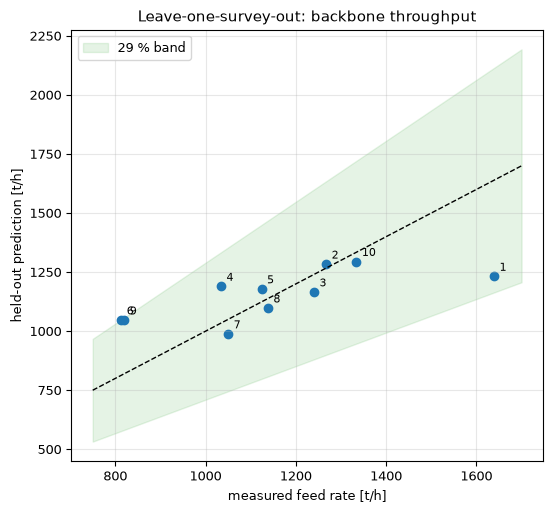

In [7]:
# Parity plot of the held-out backbone predictions against the measured throughput, with the 29 % band
fig, ax = plt.subplots(figsize=(5.6, 5.2))
line = np.array([750, 1700])
ax.fill_between(line, line * 0.71, line * 1.29, color="tab:green", alpha=0.12, label="29 % band")
ax.plot(line, line, "k--", lw=1)
ax.scatter(measured, held_out)
for s, m, p in zip(surveys, measured, held_out):
    ax.annotate(str(s.survey), (m, p), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("measured feed rate [t/h]")
ax.set_ylabel("held-out prediction [t/h]")
ax.set_title("Leave-one-survey-out: backbone throughput")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

All ten points fall inside the green band, and three of them near its edge: survey 1 is 24.8 percent below its measurement (1232 against 1639 t/h), and surveys 6 and 9 are 28.8 and 27.7 percent above theirs. The predictions occupy a narrow range, 988 to 1295 t/h, much narrower than the measurements, because the backbone only knows the setting. What the figure cannot say is whether this is good: a model that predicted the same number every time would also land inside a wide band. The comparison with that model is the next step.

**Step 3, the baseline and the optimism.** A model with no skill predicts, for the held-out survey, the mean of the other nine: the constant-mean baseline. A model that is worth anything must beat it, held out. The same document holds the in-sample (leaky) numbers, so the cell compares four models in both protocols: the backbone M0, the backbone plus a bounded residual M1, an unconstrained regression M2 and the baseline. The figure draws the pairs.

M0_backbone    held-out  12.09 %   in sample  10.95 %   optimism +1.14
M1_residual    held-out  13.45 %   in sample   8.51 %   optimism +4.94
M2_freeform    held-out  12.18 %   in sample   8.24 %   optimism +3.94
constant_mean  held-out  18.29 %   in sample  16.46 %   optimism +1.83


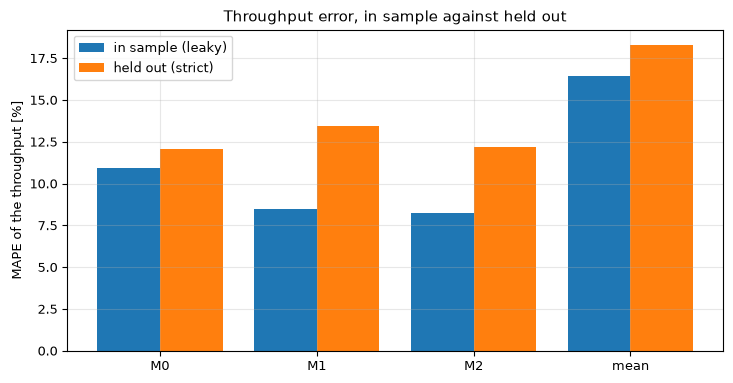

In [8]:
# Held-out (strict) and in-sample (leaky) MAPE of the four models for the throughput, and the bar chart
names = ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean")
strict = [target["strict"][m]["mape_pct"] for m in names]
leaky = [target["leaky"][m]["mape_pct"] for m in names]
for m, a, b in zip(names, strict, leaky):
    print(f"{m:14s} held-out {a:6.2f} %   in sample {b:6.2f} %   optimism {a - b:+5.2f}")
x = np.arange(len(names))
fig, ax = plt.subplots()
ax.bar(x - 0.2, leaky, 0.4, label="in sample (leaky)")
ax.bar(x + 0.2, strict, 0.4, label="held out (strict)")
ax.set_xticks(x, [m.split("_")[0] if m != "constant_mean" else "mean" for m in names])
ax.set_ylabel("MAPE of the throughput [%]")
ax.set_title("Throughput error, in sample against held out")
ax.legend()
fig.tight_layout()
plt.show()

Every model looks worse held out than in sample, which is what the protocol exists to show, and the gap is not the same for all. The backbone loses 1.1 points, the baseline 1.8, and the two models with free parameters lose 4.9 (M1) and 3.9 (M2): the more freedom, the more the in-sample number flattered. Held out, the three models are within 1.4 points of each other, 12.1, 13.5 and 12.2 percent, and all three are clearly below the baseline at 18.3 percent. The backbone has real skill, and the free-form regression with its three fitted coefficients is not better than the physics once it is held out. The figure shows the ordering; it does not show how stable it is with ten points, which is what notebook 02 examines.

## Results

**Answer:** held out, the calibrated backbone predicts the throughput of a survey with a mean absolute error of 12.09 percent, against 18.29 percent for the mean of the other nine, and 10.95 percent in sample. All ten held-out predictions are within 29 percent of the measurement, and the three largest errors are surveys 1, 6 and 9 (24.8, 28.8 and 27.7 percent); survey 1 is 407 t/h above its prediction. The optimism of the in-sample judgement is 1.14 points for the backbone and 4.94 for the model with a free residual.

The parity figure shows a narrow band of predictions against a wide band of measurements, and the bar chart the three-way ordering held out. A validator would conclude that the throughput backbone has skill that survives the hold-out, that adding free parameters bought nothing out of sample, and that the live computation reproduces the committed document. The honest limits: ten surveys of one machine make each number coarse, and the held-out protocol can say how the backbone does on a new survey of this crusher and this ore, not on another machine.

## Summary

A leave-one-survey-out fold refits the backbone's capacity base on nine surveys and predicts the tenth. On throughput the backbone beats the mean baseline held out by 6 points and is as good as an unconstrained regression, which flatters itself much more in sample. Notebook 02 asks how much to trust that on ten points, with the leaky comparison for both targets, the label-shuffle control and the residual model.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919